In [1]:
import os
import pickle
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams.update({'font.size': 15})

In [2]:
CORR = 0.25
TRUNC = 0.20
BASE_DIR = "."

root_dir = os.path.join(BASE_DIR,"experiments", "agents_10", "trunc_%.2f"%(TRUNC), "corr_%.2f"%(CORR))

print("*** DA, Optimal fairness, Optimal efficiency ***")
with open(os.path.join(root_dir, "baselines", "data.p"), 'rb') as f:
    data = pickle.load(f)

DA_FAI = data['DA_FAI']
DA_EFF = data['DA_EFF']
print(f"Deferred Acceptance : Fairness Loss = {DA_FAI:.6f}; Efficiency Gain = {DA_EFF:.6f}")
print()

OPTFAI_FAI = data['OPTFAI_FAI']
OPTFAI_EFF = data['OPTFAI_EFF']
print(f"Optimal Fairness : Fairness Loss = {OPTFAI_FAI:.6f}; Efficiency Gain = {OPTFAI_EFF:.6f}")
print()

OPTEFF_B_FAI = data['OPTEFF_B_FAI']
OPTEFF_B_EFF = data['OPTEFF_B_EFF']
print(f"Optimal Efficiency for Both : Fairness Loss = {OPTEFF_B_FAI:.6f}; Efficiency Gain = {OPTEFF_B_EFF:.6f}")
print()

OPTEFF_W_FAI = data['OPTEFF_W_FAI']
OPTEFF_W_EFF = data['OPTEFF_W_EFF']
print(f"Optimal Efficiency for Workers : Fairness Loss = {OPTEFF_W_FAI:.6f}; Efficiency Gain = {OPTEFF_W_EFF:.6f}")
print()

OPTEFF_F_FAI = data['OPTEFF_F_FAI']
OPTEFF_F_EFF = data['OPTEFF_F_EFF']
print(f"Optimal Efficiency for Firms : Fairness Loss = {OPTEFF_F_FAI:.6f}; Efficiency Gain = {OPTEFF_F_EFF:.6f}")
print()


print("*** Transformer ***")
FAI = []
EFF = []
for lambd in np.linspace(0,1,11):
    data = open(os.path.join(root_dir, "Transformer", "LOG_lambd_%.4f"%(lambd))).readlines()[-1]
    print("%.2f"%lambd, data)
    FAI.append(float(data.split(" ")[-3][:-1]))
    EFF.append(float(data.split(" ")[-1][:-1]))
        
FAI = np.array(FAI)
EFF = np.array(EFF)

*** DA, Optimal fairness, Optimal efficiency ***
Deferred Acceptance : Fairness Loss = 0.316162; Efficiency Gain = 0.618916

Optimal Fairness : Fairness Loss = 0.122180; Efficiency Gain = 0.585923

Optimal Efficiency for Both : Fairness Loss = 0.283630; Efficiency Gain = 0.760761

Optimal Efficiency for Workers : Fairness Loss = 0.137341; Efficiency Gain = 0.586065

Optimal Efficiency for Firms : Fairness Loss = 0.292212; Efficiency Gain = 0.584775

*** Transformer ***
0.00 2026-03-16 11:23:16,096:INFO:	[TEST]: 999, [fai_loss]: 0.284381, [eff_gain]: 0.231497

0.10 2026-03-16 11:21:40,541:INFO:	[TEST]: 999, [fai_loss]: 0.288608, [eff_gain]: 0.259239

0.20 2026-03-16 11:17:30,974:INFO:	[TEST]: 999, [fai_loss]: 0.289569, [eff_gain]: 0.256636

0.30 2026-03-16 11:15:52,322:INFO:	[TEST]: 999, [fai_loss]: 0.216365, [eff_gain]: 0.259241

0.40 2026-03-16 11:14:13,012:INFO:	[TEST]: 999, [fai_loss]: 0.213174, [eff_gain]: 0.256849

0.50 2026-03-16 11:11:09,000:INFO:	[TEST]: 999, [fai_loss]: 0.1795

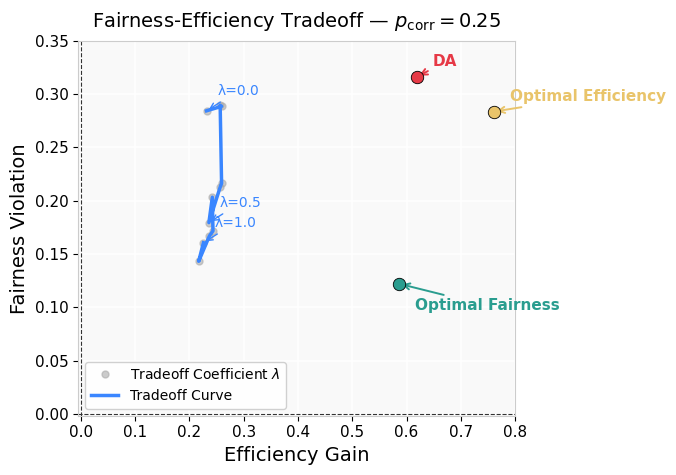

In [3]:
idx = [0,1,2,3,4,5,6,7,8,9,10]
lambdas = (np.linspace(0,1,11))
fig, ax = plt.subplots(figsize=(7, 5), facecolor='w')

# --- Background ---
ax.set_facecolor('#f9f9f9')
ax.grid(color='white', linewidth=1.2, zorder=0)
for spine in ax.spines.values():
    spine.set_edgecolor('#cccccc')

# --- Pareto frontier ---
ax.plot(EFF, FAI, 'o', color='#aaaaaa', markersize=5, alpha=0.6, label=r'Tradeoff Coefficient $\lambda$', zorder=2)
ax.plot(EFF[idx], FAI[idx], linewidth=2.5, color='#3a86ff', zorder=3, label='Tradeoff Curve')

for lam in [0.0, 0.5, 1.0]:
    i = np.argmin(np.abs(lambdas - lam))
    ax.annotate(
        f'λ={lam:.1f}',
        xy=(EFF[i], FAI[i]),
        xytext=(EFF[i] + 0.02, FAI[i] + 0.015),
        fontsize=10,
        color='#3a86ff',
        arrowprops=dict(arrowstyle='->', color='#3a86ff', lw=1.0),
    )

# --- Special points ---
special = {
    'DA':                  (DA_EFF,       DA_FAI,       '#e63946'),
    'Optimal Fairness':    (OPTFAI_EFF,   OPTFAI_FAI,   '#2a9d8f'),
    'Optimal Efficiency':  (OPTEFF_B_EFF, OPTEFF_B_FAI, '#e9c46a'),
}

offsets = {
    'DA':                 (0.03,  0.01),
    'Optimal Fairness':   (0.03, -0.025),
    'Optimal Efficiency': (0.03,  0.01),
}

for label, (x, y, color) in special.items():
    ax.scatter(x, y, s=80, color=color, zorder=5, edgecolors='k', linewidths=0.6)
    dx, dy = offsets[label]
    ax.annotate(
        label,
        xy=(x, y),
        xytext=(x + dx, y + dy),
        fontsize=11,
        color=color,
        fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=color, lw=1.4),
    )

# --- Axes ---
ax.axhline(0, color='#333333', linewidth=0.8, linestyle='--')
ax.axvline(0, color='#333333', linewidth=0.8, linestyle='--')
ax.set_xlim(-5e-3, 0.80)
ax.set_ylim(-5e-3 / 3, 0.35)
ax.set_xlabel('Efficiency Gain', fontsize=14)
ax.set_ylabel('Fairness Violation', fontsize=14)
ax.tick_params(labelsize=11)

# --- Title & legend ---
ax.set_title(r'Fairness-Efficiency Tradeoff — $p_{\mathrm{corr}}=%.2f$' % CORR, fontsize=14, pad=10)
ax.legend(fontsize=10, framealpha=0.9)

fig.tight_layout()
plt.show()